# 7 · What moved the index

The FWI of 7 May 1985 was 52.6; the day before, 21.7. What did that? This notebook walks the chain over the 48 days of the test series of the `cffdrs` R package (13 April to 30 May 1985, from Van Wagner & Pickett 1985), takes one day apart, and checks a sentence written about it.

The series is downloaded once from cffdrs (version 1.10.0, at a fixed commit) and checked by its SHA-256: it is not in this repository, because cffdrs is distributed under GPL-2.

> **A fire weather index is not an alert.** It says how easily a fire would start and spread in the weather given, not that one will. The official fire danger for Europe is published by [EFFIS](https://forest-fire.emergency.copernicus.eu/).

In [1]:
import csv
import hashlib
import io
import urllib.request
from datetime import date

import matplotlib.pyplot as plt

from fwi_chain import (
    EFFIS_FWI_CLASSES,
    STANDARD_PARAMS,
    NoonObservation,
    explain_change,
    walk_chain,
)
from fwi_chain.check import check_text
from fwi_chain.facts import day_facts

URL = (
    "https://raw.githubusercontent.com/cffdrs/cffdrs_r/"
    "4d20a303bf94febccce62f068cc8ffad0fec57c1/data/test_fwi.csv"
)
SHA256 = "9fac2165cbc4ffdadd9509943efebddba29afcb6936a4e60ab4d86fafd2a6c2a"
with urllib.request.urlopen(URL, timeout=30) as response:
    raw = response.read()
assert hashlib.sha256(raw).hexdigest() == SHA256, "not cffdrs 1.10.0"
rows = list(csv.DictReader(io.StringIO(raw.decode()), delimiter=";"))
observations = {
    date(int(r["yr"]), int(r["mon"]), int(r["day"])): NoonObservation(
        float(r["temp"]), float(r["rh"]), float(r["ws"]), float(r["prec"])
    )
    for r in rows
}
walked = walk_chain(
    observations, sorted(observations), start=None, params=STANDARD_PARAMS, max_gap_days=7
)
len(walked), walked[0].day, walked[-1].day

(48, datetime.date(1985, 4, 13), datetime.date(1985, 5, 30))

## The 48 days

The FWI, over the fire danger classes EFFIS maps it in, and the rain of each day.

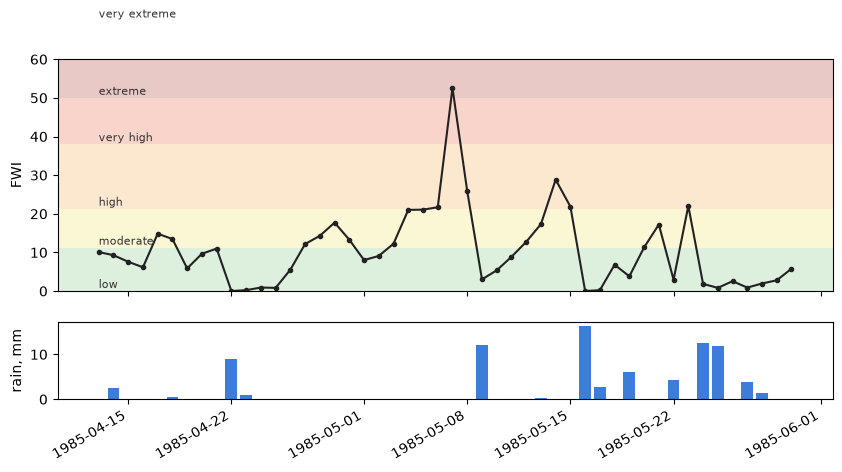

In [2]:
days = [d.day for d in walked]
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
edges = [lower for lower, _ in EFFIS_FWI_CLASSES] + [80.0]
colours = ["#7bc67b", "#f2e25a", "#f5a742", "#e8552d", "#a8281e", "#5c1a4a"]
bands = zip(EFFIS_FWI_CLASSES, edges[1:], colours, strict=True)
for (lower, name), upper, colour in bands:
    top.axhspan(lower, upper, color=colour, alpha=0.25, lw=0)
    top.text(days[0], lower + 0.8, name, fontsize=8, color="#333")
top.plot(days, [d.outputs.fwi for d in walked], color="#222", marker="o", ms=3)
top.set_ylim(0, 60)
top.set_ylabel("FWI")
bottom.bar(days, [d.observation.rain_24h_mm for d in walked], color="#3b7dd8")
bottom.set_ylabel("rain, mm")
fig.autofmt_xdate()
plt.show()

## One day, taken apart

With the very same weather as the day before, the index would still have moved: fuel that is drying keeps drying. That is the chain's memory (`carry_over`). The rest is the weather, split among the four readings: the effect of a reading is its average effect over every order in which the four could have changed (the Shapley value), so the four add up.

In [3]:
at = days.index(date(1985, 5, 7))
e = explain_change(walked[at - 1], walked[at], params=STANDARD_PARAMS)
print(f"FWI {e.fwi_yesterday:.1f} -> {e.fwi_today:.1f}  ({e.change:+.1f})")
print(f"  the chain's memory   {e.carry_over:+6.1f}")
for d in e.drivers:
    print(f"  {d.input:<18} {d.effect:+6.1f}   {d.yesterday:g} -> {d.today:g}")
assert abs(e.carry_over + sum(d.effect for d in e.drivers) - e.change) < 1e-9

FWI 21.7 -> 52.6  (+30.9)
  the chain's memory     +1.2
  wind                +18.0   12 -> 27
  humidity            +11.1   33 -> 17
  temperature          +0.6   27 -> 28
  rain                 +0.0   0 -> 0


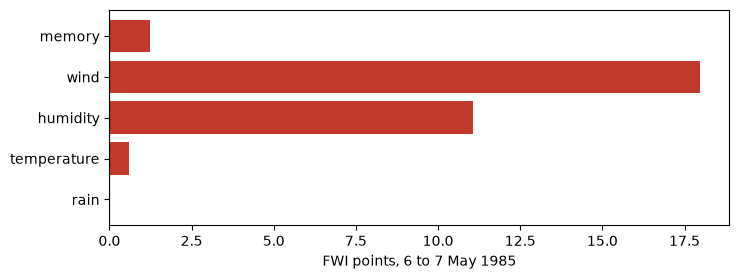

In [4]:
labels = ["memory"] + [d.input for d in e.drivers]
effects = [e.carry_over] + [d.effect for d in e.drivers]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(labels[::-1], effects[::-1], color=["#c0392b" if x > 0 else "#3b7dd8" for x in effects[::-1]])
ax.axvline(0, color="#222", lw=0.8)
ax.set_xlabel("FWI points, 6 to 7 May 1985")
plt.show()

## The same as facts, and a sentence checked against them

`day_facts` gives the day as plain data, units in the key names. A model may word these numbers; it never computes them. `check_text` finds the numbers of a text that are not facts of their unit.

In [5]:
facts = day_facts(
    walked[at], previous=walked[at - 1], params=STANDARD_PARAMS, spinup_days=30
)
{k: facts[k] for k in ("day", "observation", "codes", "effis_class", "settled")}

{'day': '1985-05-07',
 'observation': {'temperature_c': 28.0,
  'relative_humidity_pct': 17.0,
  'wind_speed_kmh': 27.0,
  'rain_24h_mm': 0.0},
 'codes': {'ffmc': 95.2,
  'dmc': 54.5,
  'dc': 102.1,
  'isi': 34.5,
  'bui': 54.3,
  'fwi': 52.6},
 'effis_class': 'extreme',
 'settled': False}

In [6]:
faithful = (
    "On 7 May 1985 the FWI rose from 21.7 to 52.6. "
    "The wind, from 12 to 27 km/h, "
    "moved it by 18.0 points; drier air, from 33 % to 17 %, by 11.1."
)
wrong = "The FWI reached 52.6 as the wind rose to 27 % and added 18.5 points."
print(check_text(faithful, facts))
for m in check_text(wrong, facts):
    print(m.text, m.fault, m.nearest)

[]
27 % unit observation.wind_speed_kmh = 27 kmh
18.5 invented None


## What this does not say

- The chain had walked 25 days on 7 May: `settled` is false. The drought code needs weeks before it stops reporting its starting value.
- The check knows a number is a fact of the right unit, not that it is said of the right thing.
- `cffdrs` gives 52.31 for this day, this library 52.56: the two follow different printings of the same constants. See `benchmarks/README.md`.